# DS-A3 | Regression Baseline and Diagnostics

**Objective:** Build an interpretable regression baseline, compare model complexity, and use residual/error diagnostics to define the model's boundary.

**Dataset:** Frozen scikit-learn Diabetes regression dataset (442 rows, 10 predictors).  
**Split:** 80/20 train-test, `random_state=42`.  
**Model selection rule:** The test set is used only once for final evaluation; Ridge hyperparameter selection uses training data only.

In [65]:
# 1. Reproducible environment and imports
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
import sklearn
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import OLSInfluence

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "Results"
RESULTS_DIR.mkdir(exist_ok=True)

DATA_PATH = DATA_DIR / "diabetes.csv"
df = pd.read_csv(DATA_PATH)

print("scikit-learn:", sklearn.__version__)
print("Data shape:", df.shape)
print(df.head())

scikit-learn: 1.5.1
Data shape: (442, 11)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


In [66]:
# 2. Data provenance and integrity check
sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("CSV SHA-256:", sha256)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Columns:", list(df.columns))

assert df.shape == (442, 11)
assert df.isna().sum().sum() == 0
assert df.duplicated().sum() == 0

CSV SHA-256: f16718c1e6602b419193b9a023dbe278ae7f85ff343158813d7040a9f7512dec
Missing values: 0
Duplicate rows: 0
Columns: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']


In [67]:
# 3. Freeze a leakage-free train/test split
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Train rows:", len(X_train))
print("Test rows:", len(X_test))

Train rows: 353
Test rows: 89


In [68]:
# 4. Baseline and candidate models
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Naive baseline: predict the training-set mean
naive_pred = np.repeat(y_train.mean(), len(y_test))

# Linear regression with scaling in a pipeline
linear = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression())
])

# Ridge regression; alpha is selected using CV on training data only
ridge = Pipeline([
    ("scale", StandardScaler()),
    ("model", Ridge())
])

alpha_grid = {"model__alpha": [0.01, 0.1, 1, 10, 100]}
ridge_search = GridSearchCV(
    ridge,
    alpha_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)
ridge_search.fit(X_train, y_train)
linear.fit(X_train, y_train)

best_ridge = ridge_search.best_estimator_
print("Selected Ridge alpha:", ridge_search.best_params_["model__alpha"])

Selected Ridge alpha: 1


In [69]:
# 5. Final frozen-test comparison
predictions = {
    "Naive mean": naive_pred,
    "Linear regression": linear.predict(X_test),
    "Ridge": best_ridge.predict(X_test)
}

rows = []
for name, pred in predictions.items():
    rows.append([
        name,
        mean_absolute_error(y_test, pred),
        mean_squared_error(y_test, pred) ** 0.5,
        r2_score(y_test, pred)
    ])

model_comparison = pd.DataFrame(rows, columns=["Model", "MAE", "RMSE", "R2"])
model_comparison.round(3)

,Model,MAE,RMSE,R2
0,Naive mean,64.006,73.222,-0.012
1,Linear regression,42.794,53.853,0.453
2,Ridge,42.812,53.777,0.454


In [70]:
# 6. Save model comparison table
model_comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
model_comparison.round(3)

,Model,MAE,RMSE,R2
0,Naive mean,64.006,73.222,-0.012
1,Linear regression,42.794,53.853,0.453
2,Ridge,42.812,53.777,0.454


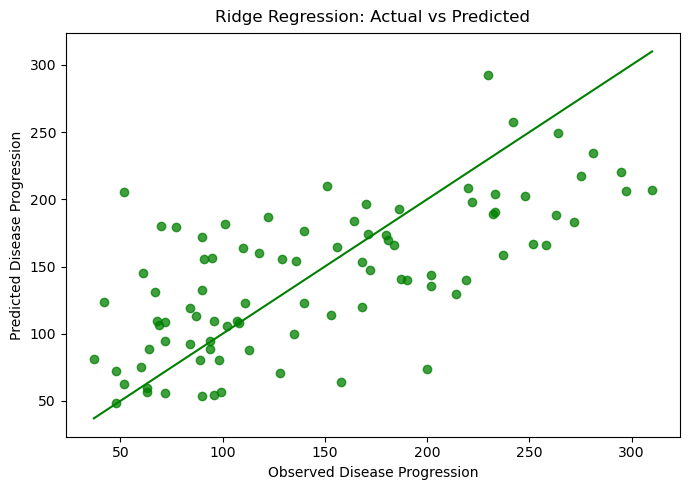

In [71]:
# 7. Actual vs predicted
ridge_test_pred = predictions["Ridge"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_test, ridge_test_pred, alpha=0.75, color="green")
mn = min(y_test.min(), ridge_test_pred.min())
mx = max(y_test.max(), ridge_test_pred.max())
ax.plot([mn, mx], [mn, mx], linewidth=1.5, color="green")
ax.set_title("Ridge Regression: Actual vs Predicted", pad=8)
ax.set_xlabel("Observed Disease Progression")
ax.set_ylabel("Predicted Disease Progression")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "01_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

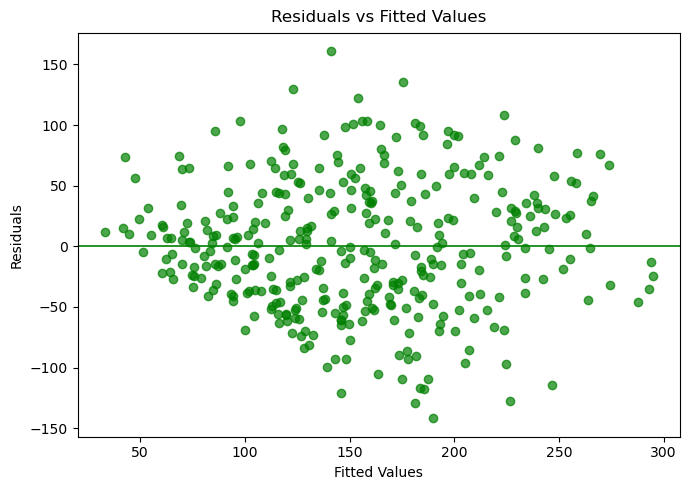

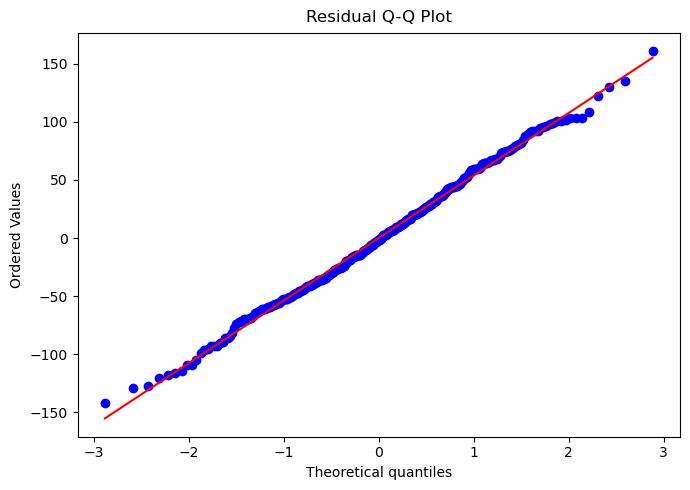

In [72]:
# 8. Residual diagnostics
ridge_train_pred = best_ridge.predict(X_train)
residuals = y_train - ridge_train_pred

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(ridge_train_pred, residuals, alpha=0.7, color="green")
ax.axhline(0, linewidth=1.2, color="green")
ax.set_title("Residuals vs Fitted Values", pad=8)
ax.set_xlabel("Fitted Values")
ax.set_ylabel("Residuals")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "02_residuals_vs_fitted.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
st.probplot(residuals, dist="norm", plot=ax)
ax.set_title("Residual Q-Q Plot", pad=8)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "03_residual_qq.png", dpi=300, bbox_inches="tight")
plt.show()

In [73]:
# 9. Formal diagnostics using an OLS fit on the training data
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
influence = OLSInfluence(ols)

cooks_distance = influence.cooks_distance[0]
bp_stat, bp_pvalue, _, _ = het_breuschpagan(ols.resid, ols.model.exog)
shapiro_pvalue = st.shapiro(ols.resid).pvalue

cook_threshold = 4 / len(X_train)
influential_count = int((cooks_distance > cook_threshold).sum())

diagnostics = pd.DataFrame({
    "Diagnostic": [
        "Breusch-Pagan p-value",
        "Shapiro-Wilk p-value",
        "Max Cook's distance",
        "Influential points (Cook's > 4/n)"
    ],
    "Value": [
        round(float(bp_pvalue), 4),
        round(float(shapiro_pvalue), 4),
        round(float(cooks_distance.max()), 4),
        influential_count
    ]
})

diagnostics

,Diagnostic,Value
0,Breusch-Pagan p-value,0.0345
1,Shapiro-Wilk p-value,0.6398
2,Max Cook's distance,0.0277
3,Influential points (Cook's > 4/n),18.0000


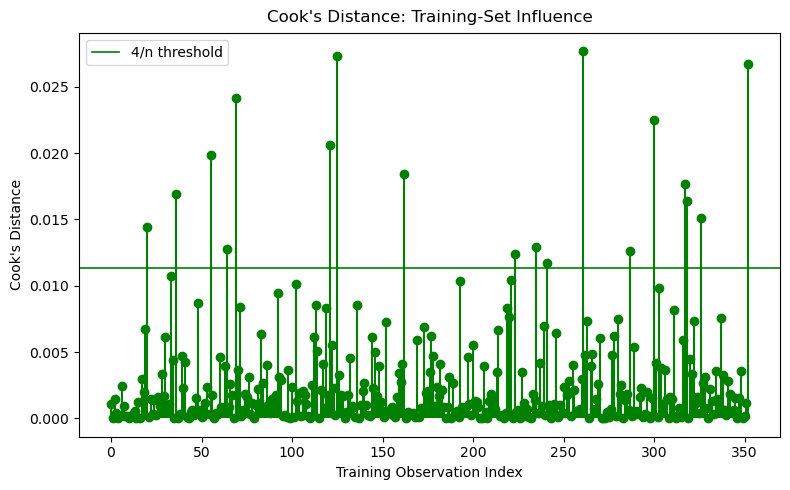

In [74]:
# 10. Cook's distance plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.stem(np.arange(len(cooks_distance)), cooks_distance,linefmt="g-",markerfmt="go", basefmt=" ")
ax.axhline(cook_threshold, linewidth=1.2,color="green", label="4/n threshold")
ax.set_title("Cook's Distance: Training-Set Influence", pad=8)
ax.set_xlabel("Training Observation Index")
ax.set_ylabel("Cook's Distance")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "05_cooks_distance.png", dpi=300, bbox_inches="tight")
plt.show()

diagnostics.to_csv(RESULTS_DIR / "diagnostics_summary.csv", index=False)

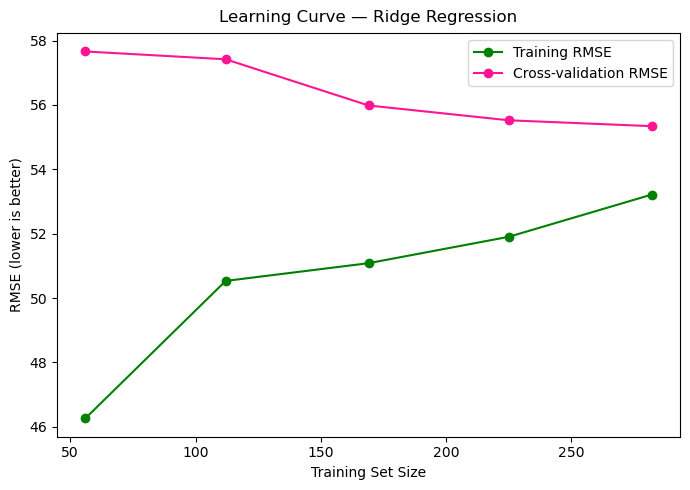

In [75]:
# 11. Learning curve
train_sizes, train_scores, val_scores = learning_curve(
    best_ridge,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    train_sizes=np.linspace(0.2, 1.0, 5)
)

train_rmse = -train_scores.mean(axis=1)
val_rmse = -val_scores.mean(axis=1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(train_sizes, train_rmse, marker="o",color="green", label="Training RMSE")
ax.plot(train_sizes, val_rmse, marker="o",color="deeppink", label="Cross-validation RMSE")
ax.set_title("Learning Curve — Ridge Regression", pad=8)
ax.set_xlabel("Training Set Size")
ax.set_ylabel("RMSE (lower is better)")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "04_learning_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [76]:
# 12. Pre-specified critical slice: centered BMI
# The BMI feature is already centered/scaled in this dataset.
slice_eval = X_test.copy()
slice_eval["y"] = y_test
slice_eval["pred"] = ridge_test_pred
slice_eval["slice"] = np.where(
    slice_eval["bmi"] <= 0,
    "BMI <= 0 (below/at centered mean)",
    "BMI > 0 (above centered mean)"
)

slice_rows = []
for name, group in slice_eval.groupby("slice"):
    slice_rows.append([
        name,
        len(group),
        mean_absolute_error(group["y"], group["pred"]),
        mean_squared_error(group["y"], group["pred"]) ** 0.5,
        r2_score(group["y"], group["pred"])
    ])

critical_slices = pd.DataFrame(
    slice_rows, columns=["Slice", "N", "MAE", "RMSE", "R2"]
)

critical_slices.round(3)

,Slice,N,MAE,RMSE,R2
0,BMI <= 0 (below/at centered mean),55,37.436,48.416,0.311
1,BMI > 0 (above centered mean),34,51.508,61.468,0.336


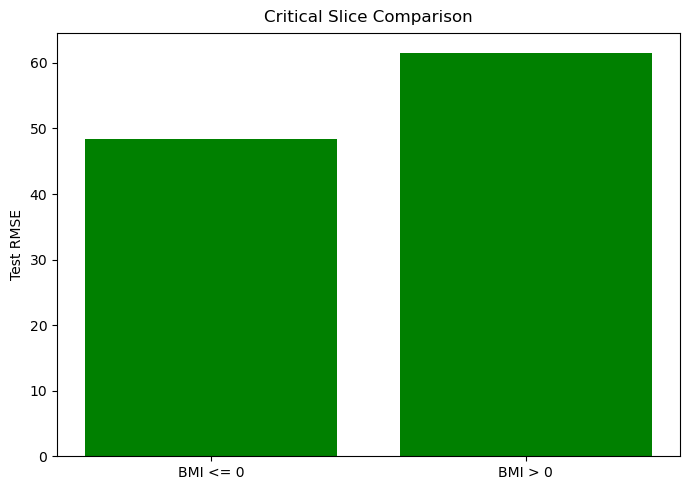

In [77]:
# 13. Save critical-slice results and figure
critical_slices.to_csv(RESULTS_DIR / "critical_slice_metrics.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(["BMI <= 0", "BMI > 0"], critical_slices["RMSE"],color="green")
ax.set_title("Critical Slice Comparison", pad=8)
ax.set_ylabel("Test RMSE")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "06_critical_slices.png", dpi=300, bbox_inches="tight")
plt.show()

In [78]:
# 14. Ridge tuning record
cv_results = pd.DataFrame(ridge_search.cv_results_)
ridge_tuning = pd.DataFrame({
    "Ridge alpha": cv_results["param_model__alpha"].astype(float),
    "Mean CV RMSE": (-cv_results["mean_test_score"]).round(3)
}).sort_values("Ridge alpha")

ridge_tuning.to_csv(RESULTS_DIR / "ridge_tuning_cv.csv", index=False)
ridge_tuning

,Ridge alpha,Mean CV RMSE
0,0.01,55.394
1,0.10,55.389
2,1.00,55.374
3,10.00,55.435
4,100.00,56.001


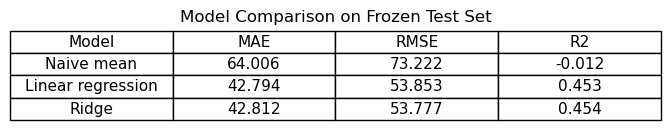

In [79]:
# 15. Export publication-ready model comparison table image
display_table = model_comparison.copy()
display_table[["MAE", "RMSE", "R2"]] = display_table[["MAE", "RMSE", "R2"]].round(3)

fig, ax = plt.subplots(figsize=(8, 1.2))
ax.axis("off")
table = ax.table(
    cellText=display_table.values,
    colLabels=display_table.columns,
    loc="center",
    cellLoc="center"
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.05, 1.45)
ax.set_title("Model Comparison on Frozen Test Set", pad=8)
fig.subplots_adjust(top=0.83, bottom=0.12)
fig.savefig(RESULTS_DIR / "07_model_comparison_table.png", dpi=300, bbox_inches="tight")
plt.show()

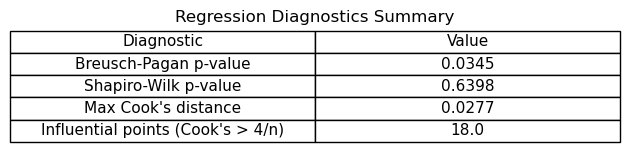

DS-A3 analysis complete. All results are in: C:\Users\allde\Downloads\DS_A3_Regression_Baseline_Diagnostics_Package\Results


In [80]:
# 16. Export diagnostics table image
fig, ax = plt.subplots(figsize=(7.5, 1.5))
ax.axis("off")
table = ax.table(
    cellText=diagnostics.values,
    colLabels=diagnostics.columns,
    loc="center",
    cellLoc="center"
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.05, 1.45)
ax.set_title("Regression Diagnostics Summary", pad=8)
fig.subplots_adjust(top=0.83, bottom=0.12)
fig.savefig(RESULTS_DIR / "08_diagnostics_summary_table.png", dpi=300, bbox_inches="tight")
plt.show()

print("DS-A3 analysis complete. All results are in:", RESULTS_DIR)